# Análisis de Loterias

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import time
import os
import random

## Extracción de datos

In [2]:
def extraer_historico(dias_atras, fecha_inicio=None):
    if fecha_inicio is None:
        fecha_inicio = datetime.now()
    else:
        fecha_inicio = datetime.strptime(fecha_inicio, "%Y-%m-%d")

    # Estos son tus nombres estándar
    loterias_objetivo = [
        'sinuano-dia', 'sinuano-noche', 
        'caribena-dia', 'caribena-noche', 
        'super-astro-sol', 'super-astro-luna'
    ]
    
    # Diccionario para unificar nombres
    mapeo_festivos = {
        'sinuano-dia-festivo': 'sinuano-dia',
        'sinuano-noche-festivo': 'sinuano-noche',
        'caribena-dia-festivo': 'caribena-dia',
        'caribena-noche-festivo': 'caribena-noche',
        'astro-luna': 'super-astro-luna',
        'astro-sol': 'super-astro-sol'
    }

    archivo_csv = 'data_loterias_completo.csv'
    reporte_faltantes = [] 

    for i in range(dias_atras):
        fecha_consulta = (fecha_inicio - timedelta(days=i)).strftime("%Y-%m-%d")
        url = f"https://api-resultadosloterias.com/api/results/{fecha_consulta}"
        
        print(f"Consultando: {fecha_consulta}...")
        
        try:
            response = requests.get(url, timeout=10)
            if response.status_code == 200:
                data = response.json()
                
                if data['status'] == 'success' and data['data']:
                    df = pd.DataFrame(data['data'])
                    
                    # --- PASO CLAVE: UNIFICAR FESTIVOS ---
                    df['slug'] = df['slug'].replace(mapeo_festivos)
                    
                    # Ahora filtramos (ya los festivos se llaman como los normales)
                    df_res = df[df['slug'].isin(loterias_objetivo)].copy()
                    df_res = df_res.drop_duplicates()
                    
                    # Auditoría de faltantes
                    encontradas_hoy = df_res['slug'].unique()
                    for loteria in loterias_objetivo:
                        if loteria not in encontradas_hoy:
                            reporte_faltantes.append(f"Lotería '{loteria}' NO disponible el {fecha_consulta}")

                    if not df_res.empty:
                        header = not os.path.exists(archivo_csv)
                        df_res.to_csv(archivo_csv, mode='a', index=False, header=header, encoding='utf-8')
                else:
                    for loteria in loterias_objetivo:
                        reporte_faltantes.append(f"DÍA SIN DATOS: '{loteria}' el {fecha_consulta}")
            
            time.sleep(0.25) 
            
        except Exception as e:
            print(f"Error en {fecha_consulta}: {e}")

    # --- REPORTE FINAL ---
    print("\n" + "="*50)
    print("RESUMEN DE AUDITORÍA (FALTANTES)")
    print("="*50)
    if reporte_faltantes:
        # Usamos sorted(set()) para que el reporte sea breve y ordenado
        for linea in sorted(set(reporte_faltantes)):
            print(f"❌ {linea}")
    else:
        print("✅ ¡Increíble! Todos los datos fueron recolectados correctamente.")
    print("="*50)
    print(f"Proceso terminado. Datos guardados en {archivo_csv}")

# Ejecución
extraer_historico(dias_atras=365)

Consultando: 2026-02-24...
Consultando: 2026-02-23...
Consultando: 2026-02-22...
Consultando: 2026-02-21...
Consultando: 2026-02-20...
Consultando: 2026-02-19...
Consultando: 2026-02-18...
Consultando: 2026-02-17...
Consultando: 2026-02-16...
Consultando: 2026-02-15...
Consultando: 2026-02-14...
Consultando: 2026-02-13...
Consultando: 2026-02-12...
Consultando: 2026-02-11...
Consultando: 2026-02-10...
Consultando: 2026-02-09...
Consultando: 2026-02-08...
Consultando: 2026-02-07...
Consultando: 2026-02-06...
Consultando: 2026-02-05...
Consultando: 2026-02-04...
Consultando: 2026-02-03...
Consultando: 2026-02-02...
Consultando: 2026-02-01...
Consultando: 2026-01-31...
Consultando: 2026-01-30...
Consultando: 2026-01-29...
Consultando: 2026-01-28...
Consultando: 2026-01-27...
Consultando: 2026-01-26...
Consultando: 2026-01-25...
Consultando: 2026-01-24...
Consultando: 2026-01-23...
Consultando: 2026-01-22...
Consultando: 2026-01-21...
Consultando: 2026-01-20...
Consultando: 2026-01-19...
C

## ANALISIS

In [46]:
class AnalizadorLoteria:
    def __init__(self, archivo_csv):
        self.archivo = archivo_csv
        self.df = None
        self.cargar_datos()

    def cargar_datos(self):
        """Carga, limpia y elimina duplicados del CSV"""
        try:
            if not os.path.exists(self.archivo):
                print(f"Archivo {self.archivo} no encontrado.")
                return

            # 1. Carga inicial
            df_raw = pd.read_csv(self.archivo, dtype={'result': str})
            
            # 2. ELIMINACIÓN DE DUPLICADOS CRÍTICA
            # Eliminamos filas que tengan la misma fecha, lotería y resultado
            df_clean = df_raw.drop_duplicates(subset=['date', 'slug', 'result']).copy()
            
            # 3. Procesamiento de fechas y limpieza de texto
            df_clean['date'] = pd.to_datetime(df_clean['date'])
            df_clean['result'] = df_clean['result'].str.zfill(4)
            
            # 4. Creación de columnas de posiciones y sumas
            for i in range(4):
                df_clean[f'pos_{i+1}'] = df_clean['result'].str[i].astype(int)
            
            df_clean['suma_total'] = df_clean[[f'pos_{1}', f'pos_{2}', f'pos_{3}', f'pos_{4}']].sum(axis=1)
            
            self.df = df_clean
            print(f"Datos cargados exitosamente. Registros únicos: {len(self.df)}")
            
        except Exception as e:
            print(f"Error al cargar: {e}")

    def filtrar_por_loteria(self, slug):
        return self.df[self.df['slug'] == slug].copy()
    
    def filtrar_por_loteria_y_dias(self, slug, dias_atras=None):
        """Filtra por lotería y opcionalmente por días hacia atrás desde el último dato"""
        data = self.filtrar_por_loteria(slug)
        
        if dias_atras is None:
            return data
        
        # Obtener la fecha máxima en los datos
        fecha_max = data['date'].max()
        fecha_limite = fecha_max - pd.Timedelta(days=dias_atras)
        
        filtered = data[data['date'] >= fecha_limite].copy()
        print(f"Analizando desde {filtered['date'].min().date()} hasta {filtered['date'].max().date()} ({dias_atras} días)")
        return filtered
    
    def analizar_frecuencia_global(self, slug, dias_atras=None):
        """Calcula cuántas veces aparece cada dígito en total (todas las posiciones)"""
        data = self.filtrar_por_loteria_y_dias(slug, dias_atras)
        if data.empty: return

        # Derretir las columnas de posiciones en una sola columna de dígitos
        posiciones = ['pos_1', 'pos_2', 'pos_3', 'pos_4']
        digitos_todos = data[posiciones].values.flatten()
        
        # Crear un conteo
        frecuencia = pd.Series(digitos_todos).value_counts().sort_index()
        
        # Graficar
        plt.figure(figsize=(10, 6))
        sns.barplot(x=frecuencia.index, y=frecuencia.values, palette='magma')
        
        periodo = f" (últimos {dias_atras} días)" if dias_atras else ""
        plt.title(f'Frecuencia Total de Dígitos (Todas las cifras) - {slug.upper()}{periodo}')
        plt.xlabel('Dígito')
        plt.ylabel('Cantidad de apariciones totales')
        
        # Añadir las etiquetas de valor sobre las barras
        for i, v in enumerate(frecuencia.values):
            plt.text(i, v + 0.1, str(v), ha='center', fontweight='bold')
            
        plt.show()
        
        return frecuencia

    def graficar_frecuencias(self, slug, dias_atras=None):
        """Crea un gráfico de barras 2x2 con las frecuencias por posición"""
        data = self.filtrar_por_loteria_y_dias(slug, dias_atras)
        if data.empty: return

        fig, axes = plt.subplots(2, 2, figsize=(12, 10))
        periodo = f" (últimos {dias_atras} días)" if dias_atras else ""
        fig.suptitle(f'Frecuencia de Dígitos por Posición - {slug.upper()}{periodo}', fontsize=16)

        for i, ax in enumerate(axes.flat):
            sns.countplot(x=f'pos_{i+1}', data=data, ax=ax, palette='viridis')
            ax.set_title(f'Cifra {i+1}')
            ax.set_xlabel('Dígito')
            ax.set_ylabel('Frecuencia')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    def obtener_numeros_frios(self, slug, dias_atras=None, top=3):
        """Calcula qué números llevan más tiempo sin salir por posición"""
        data = self.filtrar_por_loteria_y_dias(slug, dias_atras).sort_values('date', ascending=False)
        reporte = {}
        
        for i in range(1, 5):
            pos_col = f'pos_{i}'
            ultimas_apariciones = {}
            for num in range(10):
                # Buscar la fecha más reciente donde salió este número en esta posición
                fecha_num = data[data[pos_col] == num]['date'].max()
                if pd.isnull(fecha_num):
                    ultimas_apariciones[num] = 999 # Nunca ha salido
                else:
                    dias = (datetime.now() - fecha_num).days
                    ultimas_apariciones[num] = dias
            
            # Ordenar por días (los más "fríos" primero)
            frios = sorted(ultimas_apariciones.items(), key=lambda x: x[1], reverse=True)
            reporte[f'Posición {i}'] = frios[:top]
        
        return reporte
    
    def verificar_continuidad(self, slug):
        data = self.filtrar_por_loteria(slug).sort_values('date')
        data['date'] = pd.to_datetime(data['date'])
        
        # Calculamos la diferencia de días entre sorteos
        data['diff'] = data['date'].diff().dt.days
        
        huecos = data[data['diff'] > 1]
        
        if not huecos.empty:
            print(f"⚠️ Se encontraron {len(huecos)} saltos en las fechas de {slug}:")
            for index, row in huecos.iterrows():
                print(f"Faltan datos entre {(row['date'] - pd.Timedelta(days=row['diff'])).date()} y {row['date'].date()}")
        else:
            print(f"✅ Continuidad perfecta para {slug}: No faltan días en la secuencia.")
    
    def analizar_estructura(self, slug, dias_atras=None):
        data = self.filtrar_por_loteria_y_dias(slug, dias_atras)
        
        # Calcular pares e impares por sorteo
        def contar_pares(res):
            return sum(1 for d in res if int(d) % 2 == 0)

        data['pares'] = data['result'].apply(contar_pares)
        data['impares'] = 4 - data['pares']
        
        # Gráfico de distribución de sumas
        plt.figure(figsize=(10, 5))
        sns.histplot(data['suma_total'], bins=range(0, 38), kde=True, color='orange')
        periodo = f" (últimos {dias_atras} días)" if dias_atras else ""
        plt.title(f'Distribución de la Suma de Cifras - {slug}{periodo}')
        plt.xlabel('Suma de las 4 cifras (Min 0, Max 36)')
        plt.show()
        
        print(f"Promedio de suma: {data['suma_total'].mean():.2f}")
        print("Frecuencia de configuración (Pares/Impares):")
        print(data['pares'].value_counts(normalize=True).sort_index() * 100)

    def mapa_calor_dias(self, slug, dias_atras=None):
        """Genera 4 mapas de calor para ver la frecuencia de cada cifra según el día de la semana"""
        data = self.filtrar_por_loteria_y_dias(slug, dias_atras)
        if data.empty: return

        # Asegurar orden lógico de los días de la semana
        dias_ordenados = ['Lunes', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
        data['dia_semana'] = data['date'].dt.day_name()
        
        # Crear la figura con 4 subplots (2 filas, 2 columnas)
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        periodo = f" (últimos {dias_atras} días)" if dias_atras else ""
        fig.suptitle(f'Mapa de Calor: Dígitos vs Día de la Semana - {slug.upper()}{periodo}', fontsize=20)

        for i in range(1, 5):
            ax = axes.flat[i-1]
            pos_col = f'pos_{i}'
            
            # Crear tabla pivote para la posición actual
            pivot = data.pivot_table(
                index='dia_semana', 
                columns=pos_col, 
                aggfunc='size', 
                fill_value=0
            )
            
            # Reindexar para asegurar que todos los días y números (0-9) aparezcan
            pivot = pivot.reindex(index=dias_ordenados, columns=range(10), fill_value=0)

            # Dibujar el heatmap
            sns.heatmap(pivot, annot=True, cmap="YlGnBu", ax=ax, cbar=False)
            ax.set_title(f'Cifra {i}', fontsize=14)
            ax.set_xlabel('Dígito')
            ax.set_ylabel('Día de la Semana')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    def generar_sugerencia_pesada(analizador, slug, dias_atras=None):
        data = analizador.filtrar_por_loteria_y_dias(slug, dias_atras)
        sugerencia = ""
        
        for i in range(1, 5):
            # Obtener frecuencias de cada número en esa posición
            pesos = data[f'pos_{i}'].value_counts(normalize=True).sort_index()
            # Elegir un número al azar pero usando las frecuencias como probabilidad
            num_elegido = random.choices(pesos.index, weights=pesos.values)[0]
            sugerencia += str(num_elegido)
        
        periodo = f" (últimos {dias_atras} días)" if dias_atras else ""
        print(f"Sugerencia pesada para {slug}{periodo}: {sugerencia}")
        return sugerencia

    def analizar_correlacion(analizador, slug_mañana, slug_noche, dias_atras=None):
        # Unir ambos resultados por fecha
        mañana = analizador.filtrar_por_loteria_y_dias(slug_mañana, dias_atras)[['date', 'suma_total', 'pos_4']]
        noche = analizador.filtrar_por_loteria_y_dias(slug_noche, dias_atras)[['date', 'suma_total', 'pos_4']]
        
        comparativa = pd.merge(mañana, noche, on='date', suffixes=('_dia', '_noche'))
        
        corr = comparativa[['suma_total_dia', 'suma_total_noche']].corr()
        print(f"Correlación de sumas entre {slug_mañana} y {slug_noche}: {corr.iloc[0,1]:.4f}")
        
        # Gráfico de dispersión
        sns.jointplot(x='suma_total_dia', y='suma_total_noche', data=comparativa, kind="hex", color="#4CB391")
        plt.show()

    def graficar_atraso_posicional(self, slug):
        """Muestra qué tan 'atrasado' está cada número (cuántos sorteos han pasado desde su última aparición)"""
        data = self.filtrar_por_loteria(slug).sort_values('date', ascending=False)
        if data.empty: return
        
        # Resetear el índice para que la posición en el dataframe represente 'sorteos atrás'
        data = data.reset_index(drop=True)
        
        atrasos = {}
        for i in range(1, 5):
            pos = f'pos_{i}'
            ultimos = []
            for n in range(10):
                # Encontrar el índice de la primera vez que aparece el número n
                apariciones = data.index[data[pos] == n].tolist()
                if apariciones:
                    ultimos.append(apariciones[0]) # El índice 0 es el más reciente (atraso 0 = salió hoy)
                else:
                    ultimos.append(len(data)) # Si nunca ha salido en el periodo
            atrasos[f'Cifra {i}'] = ultimos

        df_atraso = pd.DataFrame(atrasos)
        
        plt.figure(figsize=(12, 6))
        
        # CORRECCIÓN: Usamos cbar_kws para pasar la etiqueta a la barra de colores
        sns.heatmap(df_atraso.T, annot=True, cmap="Reds", cbar_kws={'label': 'Cantidad de sorteos de atraso'})
        
        plt.title(f"Mapa de Atraso (Lag Chart) - {slug.upper()}", fontsize=15)
        plt.xlabel("Dígito (0-9)")
        plt.ylabel("Posición de la cifra")
        plt.show()

        df_atraso = pd.DataFrame(atrasos)
        plt.figure(figsize=(12, 6))
        sns.heatmap(df_atraso.T, annot=True, cmap="Reds", cbar_label='Sorteos de atraso')
        plt.title(f"Mapa de Atraso (Lag) - {slug}")
        plt.xlabel("Dígito (0-9)")
        plt.show()


# --- USO DEL MÓDULO ---
analizador = AnalizadorLoteria('data_loterias_completo.csv')

Datos cargados exitosamente. Registros únicos: 2053


In [4]:
analizador.verificar_continuidad('sinuano-noche')

⚠️ Se encontraron 15 saltos en las fechas de sinuano-noche:
Faltan datos entre 2025-04-10 y 2025-04-12
Faltan datos entre 2025-04-27 y 2025-04-29
Faltan datos entre 2025-06-16 y 2025-06-18
Faltan datos entre 2025-06-23 y 2025-06-25
Faltan datos entre 2025-07-14 y 2025-07-16
Faltan datos entre 2025-07-30 y 2025-08-04
Faltan datos entre 2025-08-18 y 2025-08-20
Faltan datos entre 2025-08-20 y 2025-08-22
Faltan datos entre 2025-08-27 y 2025-08-29
Faltan datos entre 2025-09-11 y 2025-09-13
Faltan datos entre 2025-09-23 y 2025-09-26
Faltan datos entre 2025-10-20 y 2025-10-22
Faltan datos entre 2025-11-24 y 2025-11-27
Faltan datos entre 2025-12-31 y 2026-01-02
Faltan datos entre 2026-02-16 y 2026-02-18


Analizando desde 2025-02-25 hasta 2026-02-23 (365 días)


C:\Users\Yilver\AppData\Local\Temp\ipykernel_16372\3483756893.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frecuencia.index, y=frecuencia.values, palette='magma')


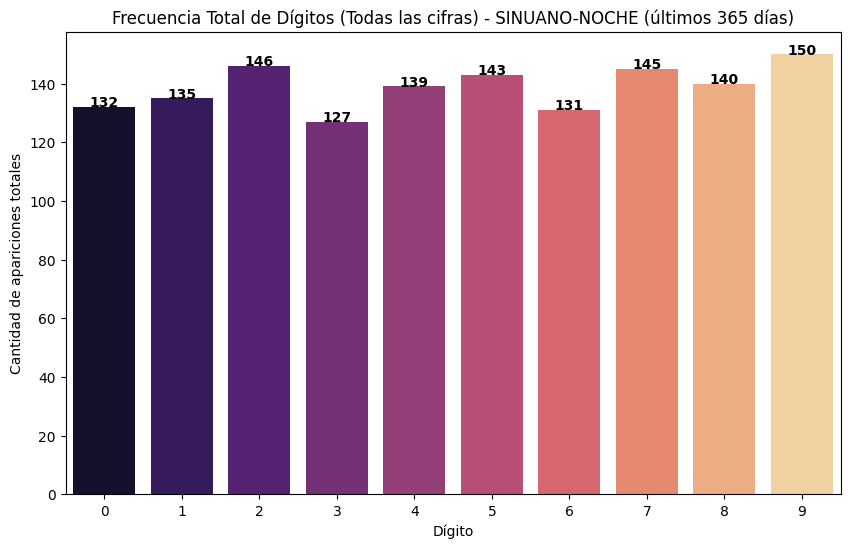

0    132
1    135
2    146
3    127
4    139
5    143
6    131
7    145
8    140
9    150
Name: count, dtype: int64

In [5]:
analizador.analizar_frecuencia_global('sinuano-noche', dias_atras=365)


ANÁLISIS DE LOS ÚLTIMOS 30 DÍAS

Analizando desde 2026-01-24 hasta 2026-02-23 (30 días)


C:\Users\Yilver\AppData\Local\Temp\ipykernel_16372\1012405231.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=f'pos_{i+1}', data=data, ax=ax, palette='viridis')
C:\Users\Yilver\AppData\Local\Temp\ipykernel_16372\1012405231.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=f'pos_{i+1}', data=data, ax=ax, palette='viridis')
C:\Users\Yilver\AppData\Local\Temp\ipykernel_16372\1012405231.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=f'pos_{i+1}', data=data, ax=ax, palette='viridis')
C:\Users\Yilver\AppData\Local\Temp\ip

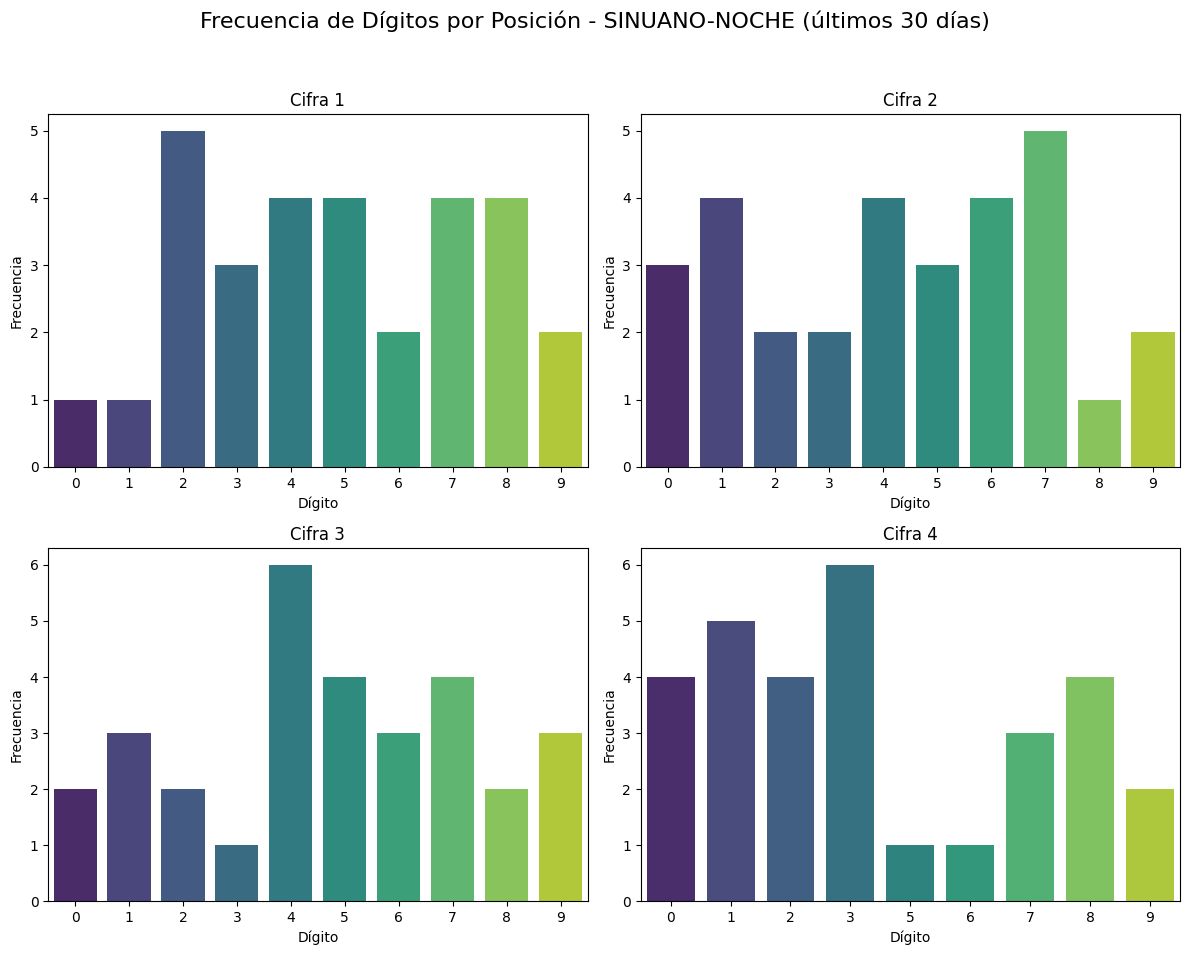

Analizando desde 2026-01-24 hasta 2026-02-23 (30 días)

--- NÚMEROS MÁS FRÍOS (Días desde su última aparición) ---
Posición 1: [(0, 26), (9, 22), (6, 21)]
Posición 2: [(5, 17), (2, 15), (9, 12)]
Posición 3: [(0, 19), (8, 17), (3, 16)]
Posición 4: [(4, 999), (6, 31), (2, 14)]


In [51]:
# Definir cantidad de días a analizar (cambiar este valor según necesites)
dias_a_analizar = 30  # Cambiar a 14, 30, 90, etc.

print(f"\n{'='*60}")
print(f"ANÁLISIS DE LOS ÚLTIMOS {dias_a_analizar} DÍAS")
print(f"{'='*60}\n")

# 1. Visualizar frecuencias de Sinuano Noche
analizador.graficar_frecuencias('sinuano-noche', dias_atras=dias_a_analizar)

# 2. Obtener reporte de números fríos
frios = analizador.obtener_numeros_frios('sinuano-noche', dias_atras=dias_a_analizar)
print("\n--- NÚMEROS MÁS FRÍOS (Días desde su última aparición) ---")
for pos, lista in frios.items():
    print(f"{pos}: {lista}")

Analizando desde 2025-02-25 hasta 2026-02-23 (365 días)


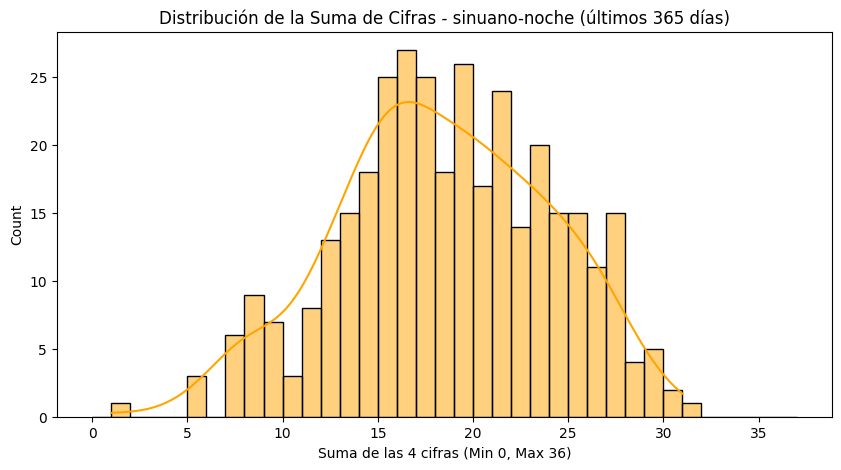

Promedio de suma: 18.30
Frecuencia de configuración (Pares/Impares):
pares
0     4.610951
1    29.682997
2    33.429395
3    26.801153
4     5.475504
Name: proportion, dtype: float64


In [8]:
# Análisis de estructura con filtro de días
analizador.analizar_estructura('sinuano-noche', dias_atras=dias_a_analizar)

Analizando desde 2025-02-25 hasta 2026-02-23 (365 días)


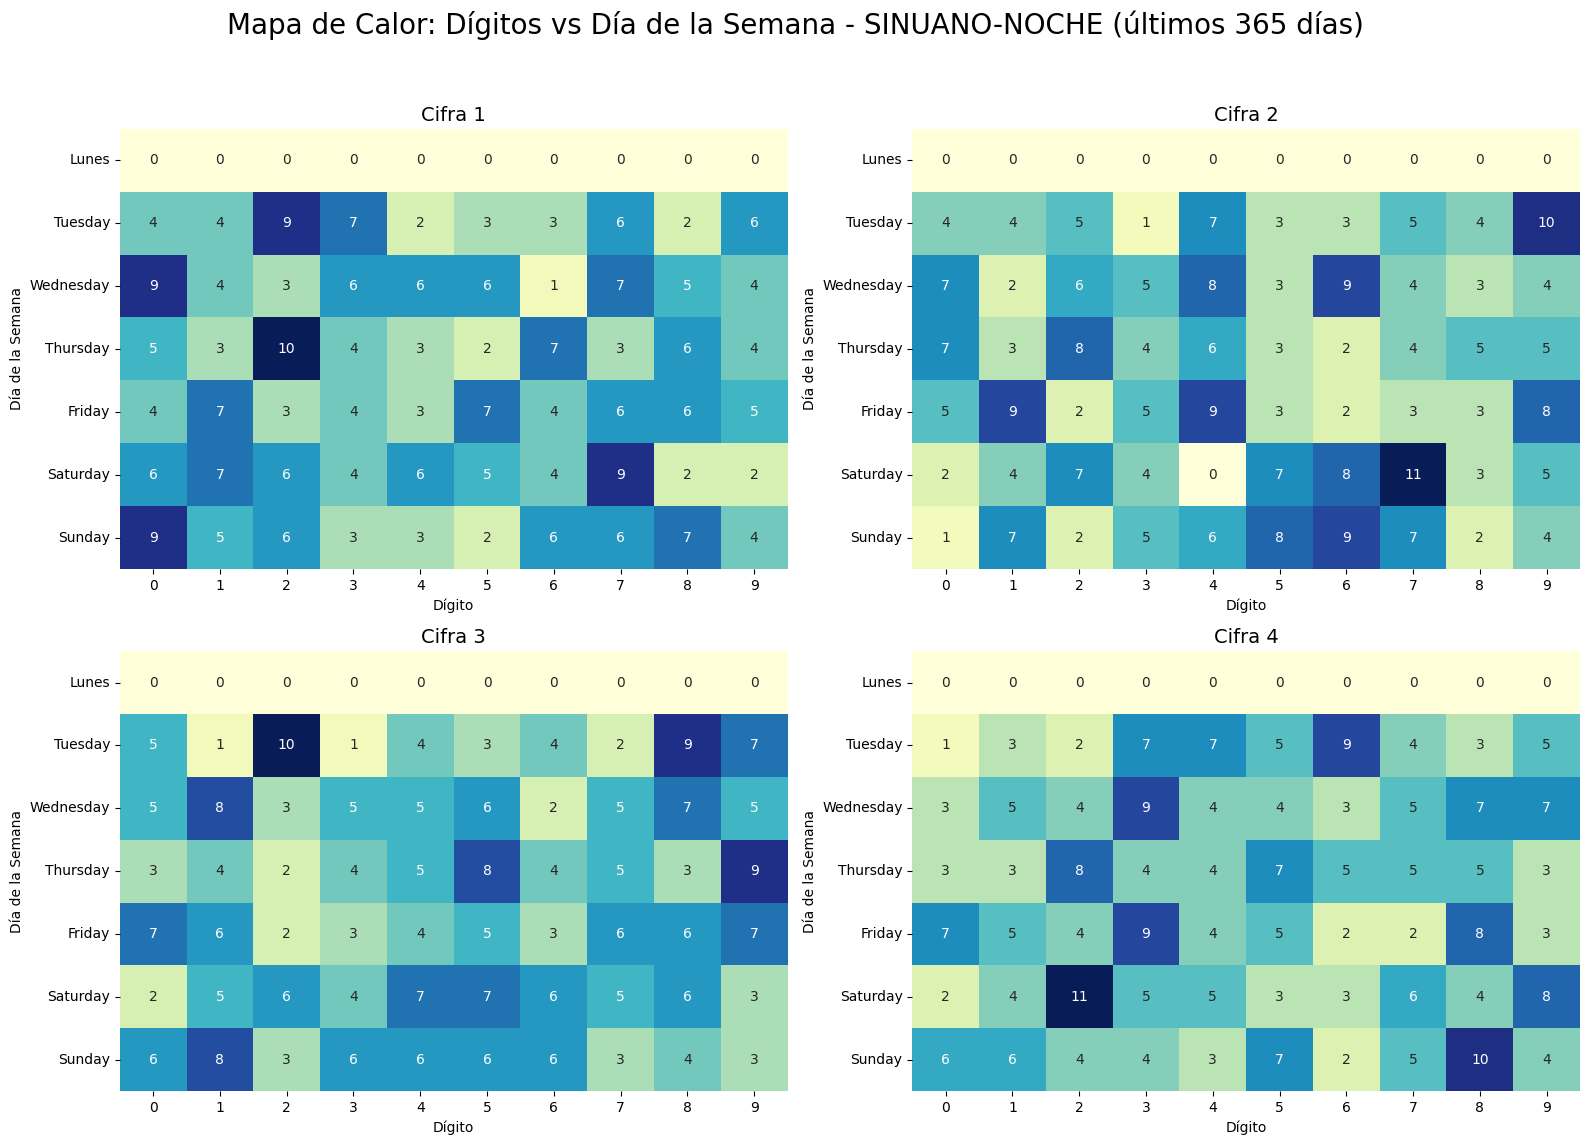

In [16]:
analizador.mapa_calor_dias('sinuano-noche', dias_atras=dias_a_analizar)

Analizando desde 2025-02-25 hasta 2026-02-24 (365 días)
Analizando desde 2025-02-25 hasta 2026-02-23 (365 días)
Correlación de sumas entre sinuano-dia y sinuano-noche: 0.0207


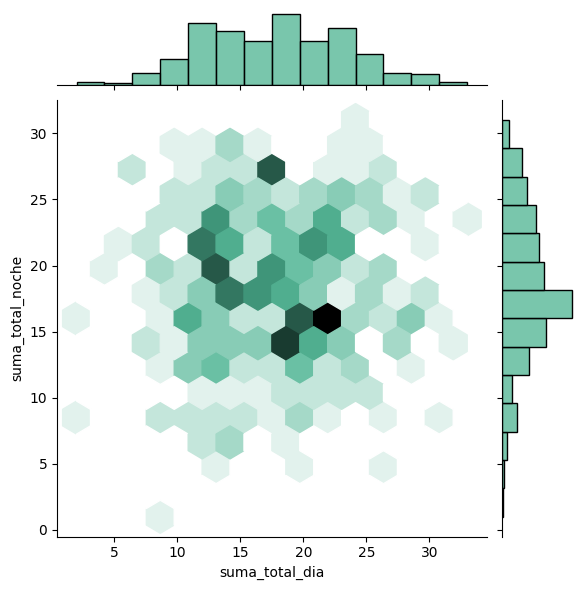

In [17]:
analizador.analizar_correlacion('sinuano-dia', 'sinuano-noche', dias_atras=dias_a_analizar)

In [42]:
analizador.generar_sugerencia_pesada('sinuano-noche', dias_atras=dias_a_analizar)

Analizando desde 2025-02-25 hasta 2026-02-23 (365 días)
Sugerencia pesada para sinuano-noche (últimos 365 días): 2109


'2109'

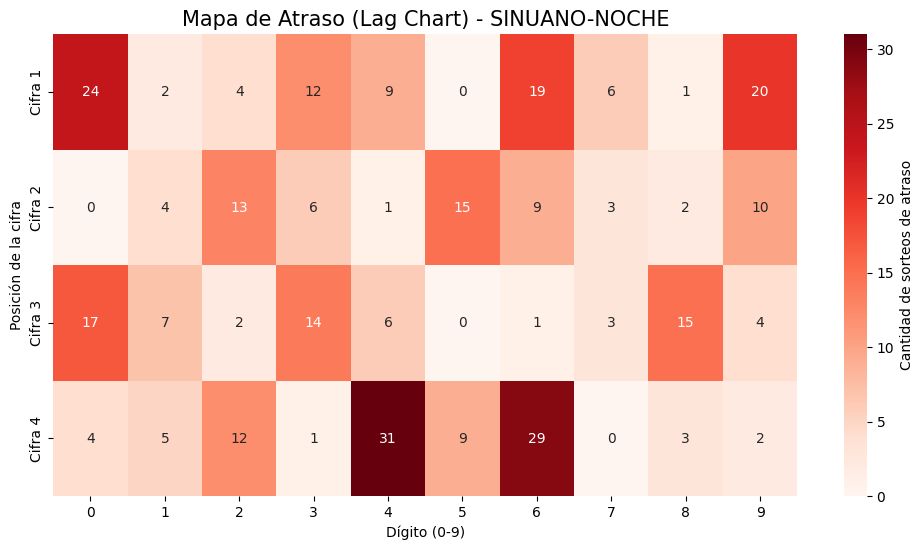

AttributeError: QuadMesh.set() got an unexpected keyword argument 'cbar_label'

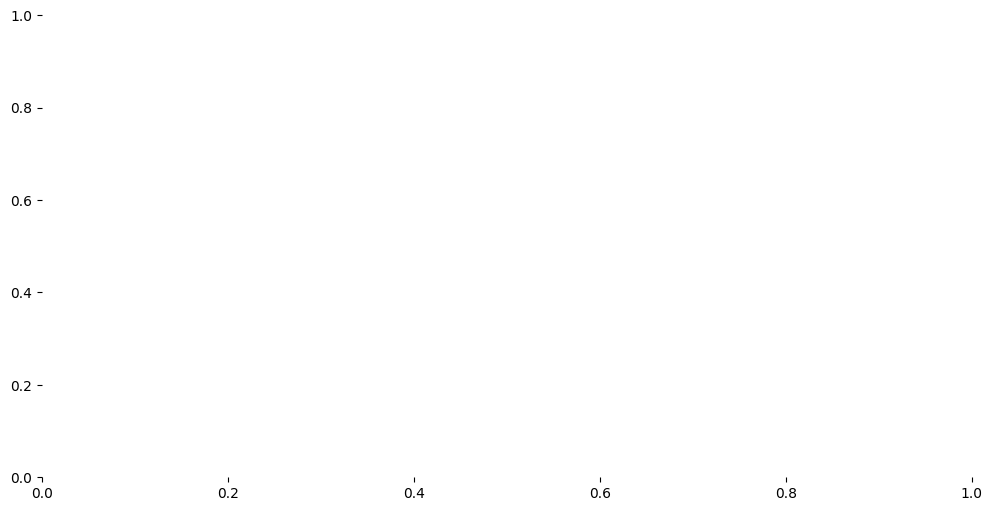

In [49]:
analizador.graficar_atraso_posicional('sinuano-noche')